<a href="https://colab.research.google.com/github/PedroNishimura/img-classifier-model/blob/main/imgClassifierModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
!pip install -q torch
!pip install -q torchvision
!pip install -q torchsummary

In [45]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from io import BytesIO
from torchsummary import summary

In [46]:
if torch.cuda.is_available():
    # Prioridade 1: GPU NVIDIA (CUDA)
    device = torch.device("cuda")
    print("Dispositivo selecionado: GPU NVIDIA (CUDA)")

elif torch.backends.mps.is_available():
    # Prioridade 2: GPU Apple (MPS)
    device = torch.device("mps")
    print("Dispositivo selecionado: GPU Apple (MPS)")

else:
    # Fallback: CPU
    device = torch.device("cpu")
    print("Dispositivo selecionado: CPU")

print(f'Usando dispositivo: {device}')

Dispositivo selecionado: GPU NVIDIA (CUDA)
Usando dispositivo: cuda


In [47]:
num_epochs = 12         # Número de épocas para treinar
batch_size = 64         # Tamanho do lote (batch)
learning_rate = 0.002   # Taxa de aprendizado

In [48]:
transformations = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

In [49]:
dataset_train = torchvision.datasets.CIFAR10(
  root = './dados',
  train = True,
  download = True,
  transform = transformations
)

dataset_teste = torchvision.datasets.CIFAR10(
  root = './dados',
  train = False,
  download = True,
  transform = transformations
)

In [50]:
loader_train = torch.utils.data.DataLoader(
  dataset_train,
  batch_size = batch_size,
  shuffle = True
)

loader_test = torch.utils.data.DataLoader(
  dataset_teste,
  batch_size = batch_size,
  shuffle = False
)

In [51]:
class_img = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

In [52]:
print(f"Número de imagens de treino: {len(dataset_train)}")
print(f"Número de imagens de teste: {len(dataset_teste)}")
print(f"Número de lotes (batches) de treino: {len(loader_train)}")
print(f"Número de lotes (batches) de teste: {len(loader_test)}")

Número de imagens de treino: 50000
Número de imagens de teste: 10000
Número de lotes (batches) de treino: 782
Número de lotes (batches) de teste: 157


In [53]:
def imshow(img):
    img = img / 2 + 0.5                          # Desnormaliza (de [-1, 1] para [0, 1])
    npimg = img.numpy()                          # Converte a imagem em formato de matriz NumPy
    plt.imshow(np.transpose(npimg, (1, 2, 0)))   # Converte de (C, H, W) para (H, W, C) - Canais (C), Altura (H) e Largura (W)
    plt.show()

In [54]:
dataiter = iter(loader_train)
images, labels = next(dataiter)

Amostra de imagens de treino:


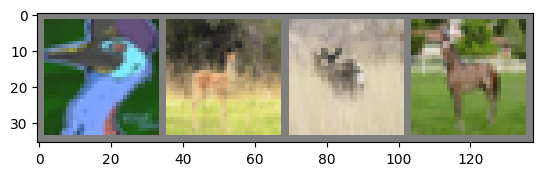

Labels:  bird  deer  deer  horse


In [55]:
print("Amostra de imagens de treino:")
imshow(torchvision.utils.make_grid(images[:4]))

print('Labels: ', ' '.join(f'{class_img[labels[j]]:5s}' for j in range(4)))

In [56]:
# Classe para criar a arquitetura do modelo
class ConvNet(nn.Module):

    # Método construtor
    def __init__(self):

        # Inicializa o construtor da classe mãe
        super(ConvNet, self).__init__()

        # Input: 3 canais de cor, Output: 6 feature maps, Kernel: 5x5
        self.conv1 = nn.Conv2d(3, 6, 5)

        # Max pooling 2x2
        self.pool = nn.MaxPool2d(2, 2)

        # Input: 6 canais (do conv1), Output: 16 feature maps, Kernel: 5x5
        self.conv2 = nn.Conv2d(6, 16, 5)

        # As imagens CIFAR-10 são 32x32
        # Após conv1 (5x5): 32-5+1 = 28 -> 28x28
        # Após pool1 (2x2): 28/2 = 14 -> 14x14
        # Após conv2 (5x5): 14-5+1 = 10 -> 10x10
        # Após pool2 (2x2): 10/2 = 5 -> 5x5
        # Tamanho achatado (flattened): 16 canais * 5 * 5 = 400 atributos

        # Camadas totalmente conectadas (Linear)
        self.fc1 = nn.Linear(16 * 5 * 5, 120) # 400 -> 120
        self.fc2 = nn.Linear(120, 84)         # 120 -> 84
        self.fc3 = nn.Linear(84, 10)          # 84 -> 10 (10 classes)

    # Método forward (passada para a frente)
    def forward(self, x):

        # Aplicando as camadas convolucionais e pooling
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        # Achatar (flatten) o tensor para a camada linear
        # Achata todas as dimensões, exceto o batch
        x = torch.flatten(x, 1)

        # Aplicando as camadas lineares com ReLU
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        # Camada de saída (sem ativação, pois a CrossEntropyLoss aplica Softmax)
        x = self.fc3(x)

        return x

In [57]:
model_img = ConvNet().to(device)

In [58]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_img.parameters(), lr = learning_rate)

In [59]:
print("\nIniciando o treinamento...\n")

# Calcula o total de passos por época (número de batches)
n_total_steps = len(loader_train)

# Loop principal de treinamento
for epoch in range(num_epochs):

    # Coloca o modelo em modo de treinamento
    model_img.train()

    # Inicializa o acumulador de perda
    running_loss = 0.0

    # Itera sobre os batches do conjunto de treino
    for i, (images, labels) in enumerate(loader_train):

        # Move os tensores (imagens e rótulos) para o dispositivo (CPU ou GPU), próximos do modelo
        images = images.to(device)
        labels = labels.to(device)

        # Passagem para frente (forward)
        # Aqui ocorre a previsão do modelo
        outputs = model_img(images)

        # Calcula o erro do modelo
        loss = criterion(outputs, labels)

        # Zera os gradientes acumulados de iterações anteriores
        optimizer.zero_grad()

        # Calcula os gradientes via backpropagation
        loss.backward()

        # Atualiza os pesos do modelo
        optimizer.step()

        # Soma o valor da perda para cálculo médio posterior
        running_loss += loss.item()

    # Após cada época, avalia o modelo no conjunto de teste (validação)
    # Coloca o modelo em modo de avaliação
    model_img.eval()

    # Desativa o cálculo de gradientes para economizar memória e tempo
    with torch.no_grad():

        n_correct = 0   # Contador de acertos
        n_samples = 0   # Contador de amostras

        # Loop sobre o conjunto de teste
        for val_images, val_labels in loader_test:

            # Move imagens e rótulos para o dispositivo
            val_images = val_images.to(device)
            val_labels = val_labels.to(device)

            # Faz a inferência no conjunto de teste
            val_outputs = model_img(val_images)

            # torch.max retorna (valor, índice) → pegamos o índice da classe prevista
            _, predicted = torch.max(val_outputs.data, 1)

            # Incrementa o total de amostras
            n_samples += val_labels.size(0)

            # Incrementa o número de acertos
            n_correct += (predicted == val_labels).sum().item()

    # Calcula a acurácia e a perda média da época
    acc = 100.0 * n_correct / n_samples
    avg_loss = running_loss / n_total_steps

    # Exibe métricas de desempenho para a época atual
    print(f'Epoch [{epoch+1}/{num_epochs}], Erro em Treino: {avg_loss:.4f}, Acurácia em Teste: {acc:.2f} %')

# Exibe mensagem final de conclusão
print('\nTreinamento finalizado.\n')


Iniciando o treinamento...

Epoch [1/12], Erro em Treino: 1.5834, Acurácia em Teste: 49.05 %
Epoch [2/12], Erro em Treino: 1.2740, Acurácia em Teste: 57.65 %
Epoch [3/12], Erro em Treino: 1.1481, Acurácia em Teste: 59.95 %
Epoch [4/12], Erro em Treino: 1.0682, Acurácia em Teste: 60.98 %
Epoch [5/12], Erro em Treino: 1.0037, Acurácia em Teste: 62.84 %
Epoch [6/12], Erro em Treino: 0.9528, Acurácia em Teste: 63.68 %
Epoch [7/12], Erro em Treino: 0.9086, Acurácia em Teste: 61.88 %
Epoch [8/12], Erro em Treino: 0.8692, Acurácia em Teste: 64.38 %
Epoch [9/12], Erro em Treino: 0.8426, Acurácia em Teste: 63.89 %
Epoch [10/12], Erro em Treino: 0.8069, Acurácia em Teste: 63.15 %
Epoch [11/12], Erro em Treino: 0.7850, Acurácia em Teste: 63.54 %
Epoch [12/12], Erro em Treino: 0.7552, Acurácia em Teste: 64.45 %

Treinamento finalizado.



In [60]:
model_img.eval()

# Desativa o cálculo de gradientes (não é necessário durante a avaliação)
with torch.no_grad():

    # Inicializa contador de acertos totais
    n_correct = 0

    # Inicializa contador total de amostras
    n_samples = 0

    # Lista para contar acertos por classe
    n_class_correct = [0 for _ in range(10)]

    # Lista para contar total de amostras por classe
    n_class_samples = [0 for _ in range(10)]

    # Loop sobre o conjunto de teste
    for images, labels in loader_test:

        # Move imagens para o dispositivo (CPU ou GPU)
        images = images.to(device)

        # Move rótulos para o mesmo dispositivo
        labels = labels.to(device)

        # Faz a inferência com o modelo
        outputs = model_img(images)

        # Obtém as classes com maior probabilidade
        _, predicted = torch.max(outputs, 1)

        # Incrementa o número total de amostras
        n_samples += labels.size(0)

        # Incrementa o número total de acertos
        n_correct += (predicted == labels).sum().item()

        # Calcular acurácia por classe
        for i in range(len(labels)):

            # Obtém o rótulo verdadeiro
            label = labels[i]

            # Obtém o rótulo previsto
            pred = predicted[i]

            # Se acertou, incrementa o contador da classe
            if (label == pred):
                n_class_correct[label] += 1

            # Incrementa o total de amostras da classe
            n_class_samples[label] += 1

    # Calcula a acurácia geral do modelo
    acc_geral = 100.0 * n_correct / n_samples

    # Exibe o resultado da acurácia geral
    print(f'Acurácia geral do modelo na base de teste: {acc_geral:.2f} %')

    # Imprime linha separadora
    print("-" * 30)

    # Loop para calcular e exibir acurácia de cada classe
    for i in range(10):

        # Se houver amostras para a classe
        if n_class_samples[i] > 0:

            # Calcula a acurácia da classe
            acc_classe = 100.0 * n_class_correct[i] / n_class_samples[i]

            # Exibe acurácia da classe
            print(f'Acurácia da classe {class_img[i]}: {acc_classe:.2f} %')

        # Caso não existam amostras da classe
        else:

            # Indica ausência de dados para a classe
            print(f'Acurácia da classe {class_img[i]}: N/A (sem amostras)')

Acurácia geral do modelo na base de teste: 64.45 %
------------------------------
Acurácia da classe plane: 72.50 %
Acurácia da classe car: 82.30 %
Acurácia da classe bird: 49.40 %
Acurácia da classe cat: 40.10 %
Acurácia da classe deer: 59.00 %
Acurácia da classe dog: 59.50 %
Acurácia da classe frog: 71.00 %
Acurácia da classe horse: 64.40 %
Acurácia da classe ship: 77.00 %
Acurácia da classe truck: 69.30 %


In [61]:
PATH = './model_img_mp7.pth'
torch.save(model_img.state_dict(), PATH)
print(f'Modelo salvo em: {PATH}')

Modelo salvo em: ./model_img_mp7.pth


In [63]:
model_load = ConvNet().to(device)
model_load.load_state_dict(torch.load(PATH))
model_load.eval()

ConvNet(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [64]:
inference_transform = transforms.Compose([
    transforms.Resize((32, 32)), # Garantir que a imagem tenha 32x32
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [73]:
def classifier_img(image_path, model):
    """
    Carrega uma imagem de um caminho local, aplica as transformações
    e faz a predição usando o modelo treinado.
    """

    try:
        # Carregar imagem do caminho local
        img_pil = Image.open(image_path).convert('RGB')
    except Exception as e:
        print(f"Erro ao carregar imagem local {image_path}: {e}")
        return

    # Aplicar transformações
    img_tensor = inference_transform(img_pil)

    # O modelo espera um lote (batch). Adicionamos uma dimensão extra [B, C, H, W]
    img_tensor = img_tensor.unsqueeze(0).to(device)

    # Fazer a predição
    model.eval() # Garantir que o modelo está em modo de avaliação
    with torch.no_grad():

        outputs = model(img_tensor)

        probabilities = F.softmax(outputs, dim=1)

        # Obter a classe com maior probabilidade
        _, predicted_idx = torch.max(outputs, 1)

    preditive_class = class_img[predicted_idx.item()]

    confidence = torch.max(probabilities).item() * 100

    # Mostrar a imagem e a predição
    plt.imshow(img_pil)

    # Usamos rf'...' (raw f-string) e $\bf{...}$ para negrito
    plt.title(rf'Classe Prevista Pelo Modelo: $\bf{{{preditive_class}}}$ (Confiança: {confidence:.2f}%)')
    plt.axis('off')
    plt.show()

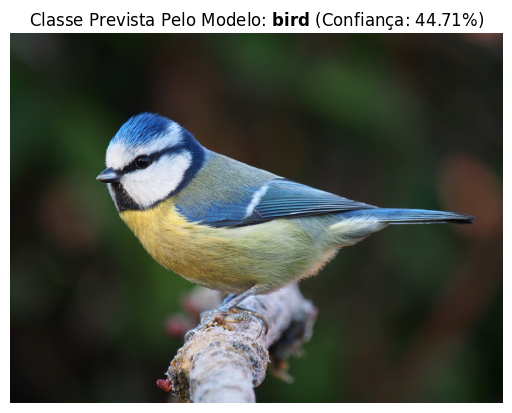

In [74]:
classifier_img("imagem1.jpg", model_load)

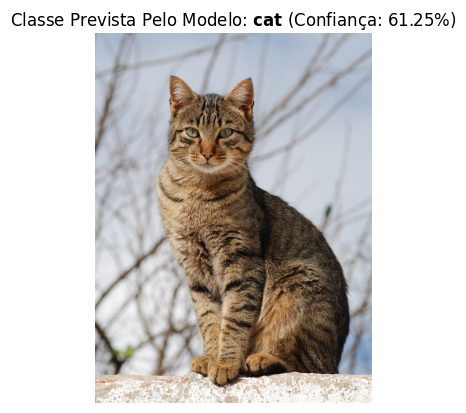

In [75]:
classifier_img("imagem2.jpg", model_load)

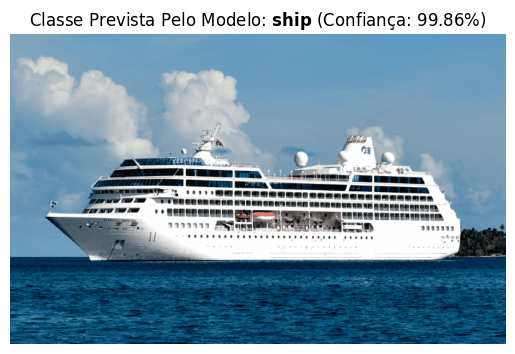

In [76]:
classifier_img("imagem3.png", model_load)

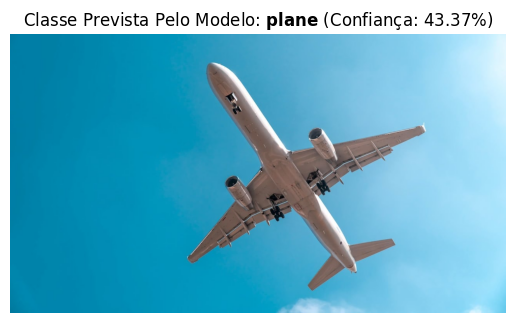

In [77]:
classifier_img("imagem4.jpg", model_load)

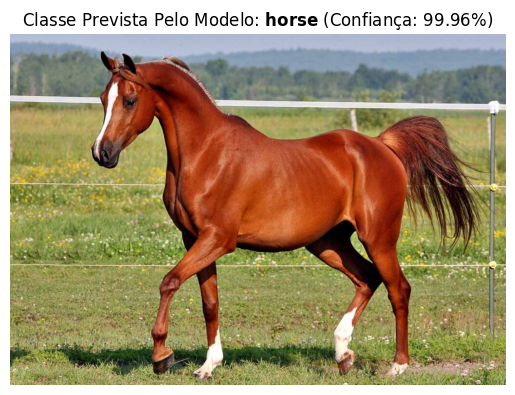

In [78]:
classifier_img("imagem5.jpg", model_load)